# Step 5c: Device 1, the fitted compact model against the paper's Fig. 6(a) and Fig. 7(a)

- **Our model:** Eq. (17) (`current.py`) + non-linear access resistance [T, Eqs. 5.1–5.3] (`access.py`), with the values in `params_device1.json` from the Step 5b fit. Fitted [CALIBRATE]: U₀, V_SAT0, θ_SAT2. Everything else is fixed and labelled in that file.
- **Paper [P]:** the measured points ([11], CW) and the paper's own model line, read from the PDF's vectors.
- **Two checks:** how well each model fits the measurement (rms), and how far our line is from the paper's line.

In [1]:
import json
import numpy as np
import matplotlib.pyplot as plt
from access import id_ext

with open("params_device1.json") as f:
    params = json.load(f)
P = {**params["fixed"], **params["fitted [CALIBRATE]"]}
for key in ("n_acc_cm2", "l_sg", "l_gd"):          # these live in access.py, not in the function arguments
    P.pop(key)
print("fitted:", {k: float(f"{v:.4g}") for k, v in params["fitted [CALIBRATE]"].items()})

def load(name):
    """Read one paper_data CSV (2 comment lines + 1 header line) into a numpy array."""
    return np.loadtxt(f"paper_data/{name}.csv", delimiter=",", skiprows=3)

id_meas, gm_meas = load("fig6a_measured_ID"), load("fig6a_measured_gm")
id_pmod, gm_pmod = load("fig6a_paper_model_ID"), load("fig6a_paper_model_gm")
out_meas, out_pmod = load("fig7a_measured"), load("fig7a_paper_model")

def model(V_GS, V_DS):
    """Our fitted model: external drain current in mA."""
    return id_ext(V_GS, V_DS, **P) * 1e3

V = np.linspace(-3.0, 3.0, 601)                     # V_GS grid, 10 mV steps
I_model = np.array([model(v, 10.0) for v in V])     # mA, at V_DS = 10 V
gm_model = np.gradient(I_model, V)                  # mS
VGS_FAMILY = np.arange(-1.0, 3.01, 0.5)
VD = np.linspace(0.0, 10.0, 101)
I_out = {vg: np.array([model(vg, vd) for vd in VD]) for vg in VGS_FAMILY}
print(f"model ready: {len(V)} transfer points, {len(VGS_FAMILY)} output curves")

fitted: {'u0': 0.06254, 'vsat0': 75190.0, 'th2': 0.5888}
model ready: 601 transfer points, 9 output curves


In [2]:
def at(curve, x):
    """Value of a curve (column 0 = x, column 1 = y) at x, by straight-line interpolation."""
    return np.interp(x, curve[:, 0], curve[:, 1])

def out_at(data, vg, vd):
    """Output-curve current at (V_GS, V_DS) from a Fig. 7(a) file (columns V_GS, V_DS, I_D)."""
    s = data[data[:, 0] == vg]
    return np.interp(vd, s[:, 1], s[:, 2])

ours = np.column_stack([V, I_model])
ours_gm = np.column_stack([V, gm_model])
ours_out = np.array([[vg, vd, i] for vg in VGS_FAMILY for vd, i in zip(VD, I_out[vg])])

rows = [("I_D at V_GS = 0 V (mA)",           at(id_meas, 0.0), at(id_pmod, 0.0), at(ours, 0.0)),
        ("I_D at V_GS = +3 V (mA)",          at(id_meas, 3.0), at(id_pmod, 3.0), at(ours, 3.0)),
        ("g_M peak (mS)",                    gm_meas[:, 1].max(), gm_pmod[:, 1].max(), gm_model.max()),
        ("V_GS at the g_M peak (V)",         gm_meas[gm_meas[:, 1].argmax(), 0], gm_pmod[gm_pmod[:, 1].argmax(), 0],
                                             V[gm_model.argmax()]),
        ("g_M at V_GS = +2.4 V (mS)",        at(gm_meas, 2.4), at(gm_pmod, 2.4), at(ours_gm, 2.4)),
        ("I_D at V_GS = 3, V_DS = 1 V (mA)", out_at(out_meas, 3.0, 1.0), out_at(out_pmod, 3.0, 1.0), model(3.0, 1.0))]
print(f"{'':34s}{'measured':>10s}{'paper model':>13s}{'our model':>11s}")
for name, a, b, c in rows:
    print(f"{name:34s}{a:10.2f}{b:13.2f}{c:11.2f}")

# rms errors on the same points the fit used (Step 5b)
m6 = id_meas[id_meas[:, 0] > -1.4]
g6 = gm_meas[(gm_meas[:, 0] > -1.4) & (gm_meas[:, 0] < 2.95)]
m7 = out_meas[out_meas[:, 1] > 0]
rms = lambda d: np.sqrt(np.mean(np.square(d)))
paper_err = (rms(at(id_pmod, m6[:, 0]) - m6[:, 1]),
             rms([out_at(out_pmod, vg, vd) - i for vg, vd, i in m7]),
             rms(at(gm_pmod, g6[:, 0]) - g6[:, 1]))
our_err = (rms(at(ours, m6[:, 0]) - m6[:, 1]),
           rms([out_at(ours_out, vg, vd) - i for vg, vd, i in m7]),
           rms(at(ours_gm, g6[:, 0]) - g6[:, 1]))
gap = (rms(at(ours, m6[:, 0]) - at(id_pmod, m6[:, 0])),
       rms([out_at(ours_out, vg, vd) - out_at(out_pmod, vg, vd) for vg, vd, i in m7]),
       rms(at(ours_gm, g6[:, 0]) - at(gm_pmod, g6[:, 0])))
print()
print(f"{'rms error':34s}{'paper vs meas.':>15s}{'ours vs meas.':>15s}{'ours vs paper':>15s}")
for name, a, b, c in zip(["Fig. 6(a) I_D (mA)", "Fig. 7(a) I_D (mA)", "Fig. 6(a) g_M (mS)"], paper_err, our_err, gap):
    print(f"{name:34s}{a:15.2f}{b:15.2f}{c:15.2f}")

                                    measured  paper model  our model
I_D at V_GS = 0 V (mA)                 39.05        39.51      39.19
I_D at V_GS = +3 V (mA)               151.90       152.05     153.40
g_M peak (mS)                          42.59        42.52      43.93
V_GS at the g_M peak (V)                0.30         0.15       0.24
g_M at V_GS = +2.4 V (mS)              33.41        33.26      33.18
I_D at V_GS = 3, V_DS = 1 V (mA)       36.62        36.58      37.34

rms error                          paper vs meas.  ours vs meas.  ours vs paper
Fig. 6(a) I_D (mA)                           0.51           1.10           1.20
Fig. 7(a) I_D (mA)                           1.27           1.72           0.96
Fig. 6(a) g_M (mS)                           0.96           1.12           0.97


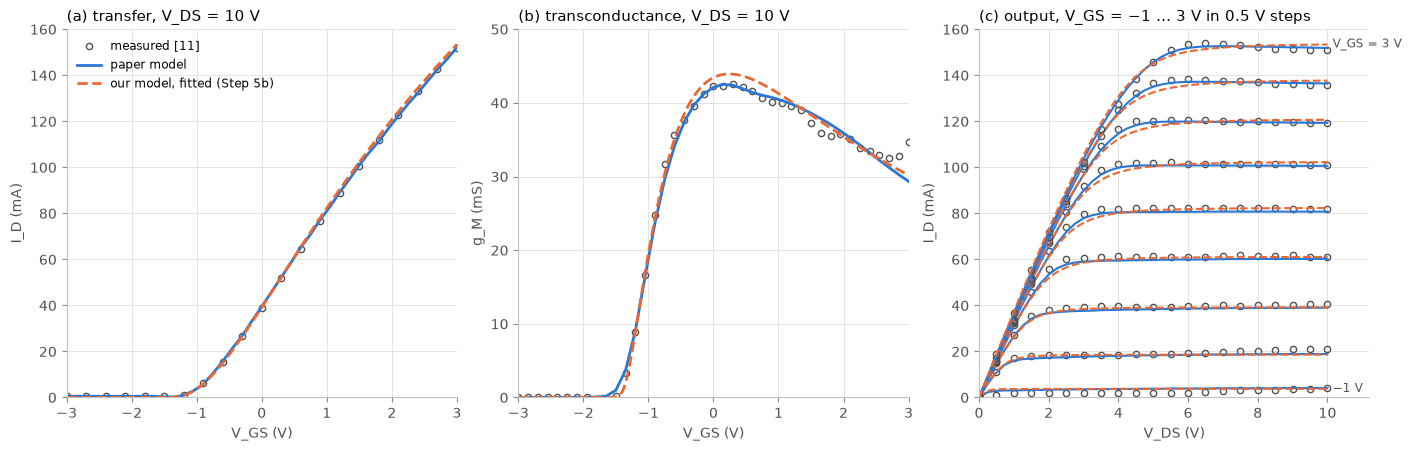

In [3]:
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#52514e", "#898781", "#e1e0d9"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED,
                     "xtick.labelcolor": INK, "ytick.labelcolor": INK,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})
meas_style = dict(ls="none", marker="o", mfc="none", mec=INK, ms=4.5)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14, 4.4), constrained_layout=True)

ax1.plot(id_meas[:, 0], id_meas[:, 1], **meas_style, label="measured [11]")
ax1.plot(id_pmod[:, 0], id_pmod[:, 1], color=BLUE, lw=2, label="paper model")
ax1.plot(V, I_model, color=ORANGE, lw=2, ls="--", label="our model, fitted (Step 5b)")
ax1.set_ylabel("I_D (mA)"); ax1.set_ylim(0, 160)
ax1.set_title("(a) transfer, V_DS = 10 V", loc="left", fontsize=11)
ax1.legend(loc="upper left", fontsize=8.5)

ax2.plot(gm_meas[:, 0], gm_meas[:, 1], **meas_style)
ax2.plot(gm_pmod[:, 0], gm_pmod[:, 1], color=BLUE, lw=2)
ax2.plot(V, gm_model, color=ORANGE, lw=2, ls="--")
ax2.set_ylabel("g_M (mS)"); ax2.set_ylim(0, 50)
ax2.set_title("(b) transconductance, V_DS = 10 V", loc="left", fontsize=11)

for ax in (ax1, ax2):
    ax.set_xlim(-3, 3); ax.set_xlabel("V_GS (V)")

for vg in VGS_FAMILY:
    s = out_meas[out_meas[:, 0] == vg]
    ax3.plot(s[:, 1], s[:, 2], **meas_style)
    s = out_pmod[out_pmod[:, 0] == vg]
    ax3.plot(s[:, 1], s[:, 2], color=BLUE, lw=1.5)
    ax3.plot(VD, I_out[vg], color=ORANGE, lw=1.5, ls="--")
ax3.text(10.15, I_out[3.0][-1], "V_GS = 3 V", va="center", fontsize=8.5, color=INK)
ax3.text(10.15, I_out[-1.0][-1], "−1 V", va="center", fontsize=8.5, color=INK)
ax3.set_xlim(0, 11.2); ax3.set_ylim(0, 160)
ax3.set_xlabel("V_DS (V)"); ax3.set_ylabel("I_D (mA)")
ax3.set_title("(c) output, V_GS = −1 … 3 V in 0.5 V steps", loc="left", fontsize=11)

for ax in (ax1, ax2, ax3):
    ax.grid(True, color=GRID, lw=0.6)
fig.savefig("figures/step5c_device1_final.png", dpi=200)
plt.show()